Data Wrangling Coursework Project

Group Members: AINE OWEN-25/08/BDA/U/0002
               NANZIRI TRACY BEATRICE-25/08/BDA/U/0001
               ASIIMWE ISAAC GIVEN -25/08/BDA/U/0008

Objective:

Data Collection & Ingestion
Data Auditing
Missing Value Handling
Duplicate Detection and Removal
Outlier Detection and Treatment
Exploratory Data Analysis (EDA)
Feature Transformation & Engineering
Dataset Export


Importing libraries

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

loading dataset

In [2]:
train_df = pd.read_csv("train_data 1.csv")

test_df = pd.read_excel("test_data 2.xlsx")

print("Training Dataset Shape:", train_df.shape)
print("Test Dataset Shape:", test_df.shape)

Training Dataset Shape: (7160, 14)
Test Dataset Shape: (3069, 13)


In [3]:
train_df.head()


,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,Date_of_Occupancy,NumberOfWindows,Geo_Code,Claim
0,H14663,2013,1.0,0,N,V,V,U,290.0,1,1960.0,.,1053,0
1,H2037,2015,1.0,0,V,N,O,R,490.0,1,1850.0,4,1053,0
2,H3802,2014,1.0,0,N,V,V,U,595.0,1,1960.0,.,1053,0
3,H3834,2013,1.0,0,V,V,V,U,2840.0,1,1960.0,.,1053,0
4,H5053,2014,1.0,0,V,N,O,R,680.0,1,1800.0,3,1053,0


In [4]:
test_df.head()

,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,Date_of_Occupancy,NumberOfWindows,Geo_Code
0,H11920,2013,1.000000,0,V,N,O,R,300.0,1,1960.0,3,3310
1,H11921,2016,0.997268,0,V,N,O,R,300.0,1,1960.0,3,3310
2,H9805,2013,0.369863,0,V,V,V,U,790.0,1,1960.0,.,3310
3,H7493,2014,1.000000,0,V,N,O,R,1405.0,1,2004.0,3,3321
4,H7494,2016,1.000000,0,V,N,O,R,1405.0,1,2004.0,3,3321


Data Auditing: data types, missing values, duplicates, Data inconsistences

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7160 entries, 0 to 7159
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer Id         7160 non-null   object 
 1   YearOfObservation   7160 non-null   int64  
 2   Insured_Period      7160 non-null   float64
 3   Residential         7160 non-null   int64  
 4   Building_Painted    7160 non-null   object 
 5   Building_Fenced     7160 non-null   object 
 6   Garden              7153 non-null   object 
 7   Settlement          7160 non-null   object 
 8   Building Dimension  7054 non-null   float64
 9   Building_Type       7160 non-null   int64  
 10  Date_of_Occupancy   6652 non-null   float64
 11  NumberOfWindows     7160 non-null   object 
 12  Geo_Code            7058 non-null   object 
 13  Claim               7160 non-null   int64  
dtypes: float64(3), int64(4), object(7)
memory usage: 783.3+ KB


In [6]:
train_df.describe(include='all')

,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,Date_of_Occupancy,NumberOfWindows,Geo_Code,Claim
count,7160,7160.000000,7160.000000,7160.000000,7160,7160,7153,7160,7054.000000,7160.000000,6652.000000,7160,7058,7160.000000
unique,7160,NaN,NaN,NaN,2,2,2,2,NaN,NaN,NaN,11,1307,NaN
top,H7470,NaN,NaN,NaN,V,N,O,R,NaN,NaN,NaN,.,6088,NaN
freq,1,NaN,NaN,NaN,5382,3608,3602,3610,NaN,NaN,NaN,3551,143,NaN
mean,NaN,2013.669553,0.909758,0.305447,NaN,NaN,NaN,NaN,1883.727530,2.186034,1964.456404,NaN,NaN,0.228212
std,NaN,1.383769,0.239756,0.460629,NaN,NaN,NaN,NaN,2278.157745,0.940632,36.002014,NaN,NaN,0.419709
min,NaN,2012.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,1.000000,1.000000,1545.000000,NaN,NaN,0.000000
25%,NaN,2012.000000,0.997268,0.000000,NaN,NaN,NaN,NaN,528.000000,2.000000,1960.000000,NaN,NaN,0.000000
50%,NaN,2013.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,1083.000000,2.000000,1970.000000,NaN,NaN,0.000000
75%,NaN,2015.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,2289.750000,3.000000,1980.000000,NaN,NaN,0.000000


In [7]:
train_df.isnull().sum()

Customer Id             0
YearOfObservation       0
Insured_Period          0
Residential             0
Building_Painted        0
Building_Fenced         0
Garden                  7
Settlement              0
Building Dimension    106
Building_Type           0
Date_of_Occupancy     508
NumberOfWindows         0
Geo_Code              102
Claim                   0
dtype: int64

In [8]:
train_df.dtypes


Customer Id            object
YearOfObservation       int64
Insured_Period        float64
Residential             int64
Building_Painted       object
Building_Fenced        object
Garden                 object
Settlement             object
Building Dimension    float64
Building_Type           int64
Date_of_Occupancy     float64
NumberOfWindows        object
Geo_Code               object
Claim                   int64
dtype: object

Checking missing values

In [9]:
train_df.replace('.', np.nan, inplace=True)
test_df.replace('.', np.nan, inplace=True)

In [10]:
train_df.isnull().sum()

Customer Id             0
YearOfObservation       0
Insured_Period          0
Residential             0
Building_Painted        0
Building_Fenced         0
Garden                  7
Settlement              0
Building Dimension    106
Building_Type           0
Date_of_Occupancy     508
NumberOfWindows         0
Geo_Code              102
Claim                   0
dtype: int64

Handling duplicates

In [11]:
duplicates = train_df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 0


In [12]:
train_df.drop_duplicates(inplace=True)

print("New Shape:", train_df.shape)

New Shape: (7160, 14)


Handling missing values

In [13]:
numerical_cols = train_df.select_dtypes(include=np.number).columns

categorical_cols = train_df.select_dtypes(exclude=np.number).columns

In [14]:
for col in numerical_cols:
    train_df[col].fillna(train_df[col].median(), inplace=True)

for col in categorical_cols:
    train_df[col].fillna(train_df[col].mode()[0], inplace=True)

In [15]:
train_df.isnull().sum()

Customer Id           0
YearOfObservation     0
Insured_Period        0
Residential           0
Building_Painted      0
Building_Fenced       0
Garden                0
Settlement            0
Building Dimension    0
Building_Type         0
Date_of_Occupancy     0
NumberOfWindows       0
Geo_Code              0
Claim                 0
dtype: int64

Cleaning "NumberOfWindows" Feature

In [16]:
train_df['NumberOfWindows'] = train_df['NumberOfWindows'].replace('>=10', 10)
test_df['NumberOfWindows'] = test_df['NumberOfWindows'].replace('>=10', 10)

train_df['NumberOfWindows'] = pd.to_numeric(
    train_df['NumberOfWindows'],
    errors='coerce'
)

test_df['NumberOfWindows'] = pd.to_numeric(
    test_df['NumberOfWindows'],
    errors='coerce'
)

Outlier Detection Using IQR

In [17]:
numeric_columns = train_df.select_dtypes(include=['int64','float64']).columns

numeric_columns

Index(['YearOfObservation', 'Insured_Period', 'Residential',
       'Building Dimension', 'Building_Type', 'Date_of_Occupancy',
       'NumberOfWindows', 'Claim'],
      dtype='object')

In [18]:
for col in numeric_columns:

    if col != 'Claim':

        Q1 = train_df[col].quantile(0.25)
        Q3 = train_df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5*IQR
        upper = Q3 + 1.5*IQR

        train_df[col] = np.where(
            train_df[col] > upper,
            upper,
            train_df[col]
        )

        train_df[col] = np.where(
            train_df[col] < lower,
            lower,
            train_df[col]
        )

Exploratory Data Analysis, EDA

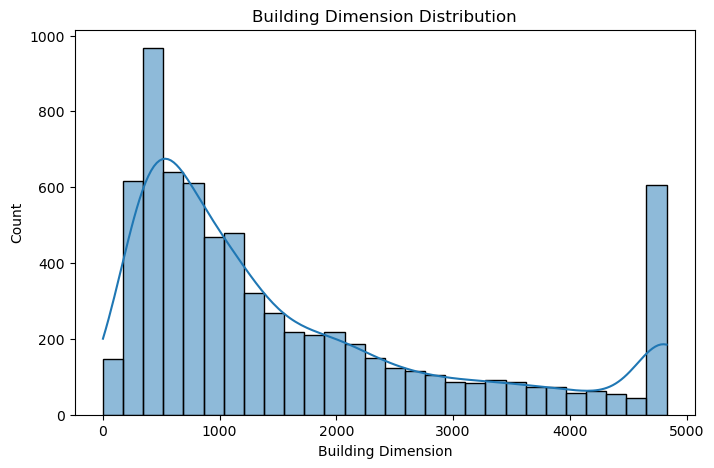

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(train_df['Building Dimension'],
             kde=True)

plt.title('Building Dimension Distribution')
plt.show()

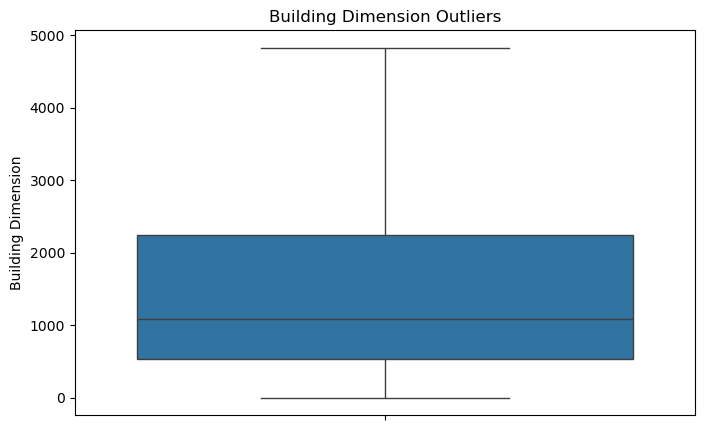

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(y=train_df['Building Dimension'])
plt.title('Building Dimension Outliers')
plt.show()

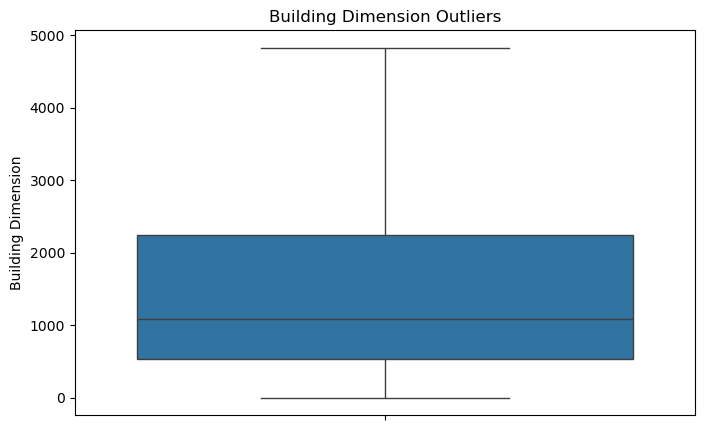

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(y=train_df['Building Dimension'])
plt.title('Building Dimension Outliers')
plt.show()

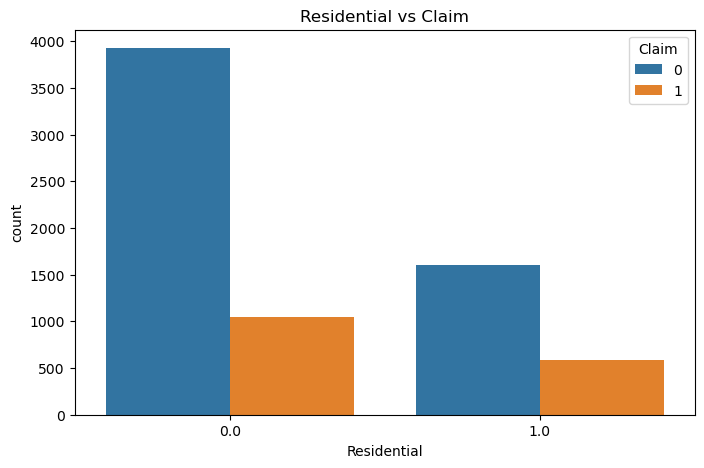

In [22]:
plt.figure(figsize=(8,5))
sns.countplot(
    x='Residential',
    hue='Claim',
    data=train_df
)

plt.title('Residential vs Claim')
plt.show()

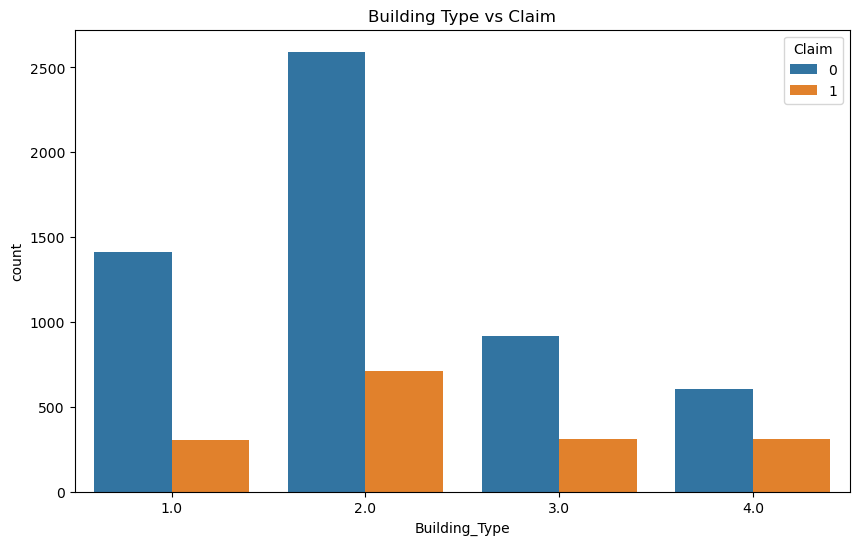

In [23]:
plt.figure(figsize=(10,6))

sns.countplot(
    x='Building_Type',
    hue='Claim',
    data=train_df
)

plt.title('Building Type vs Claim')
plt.show()

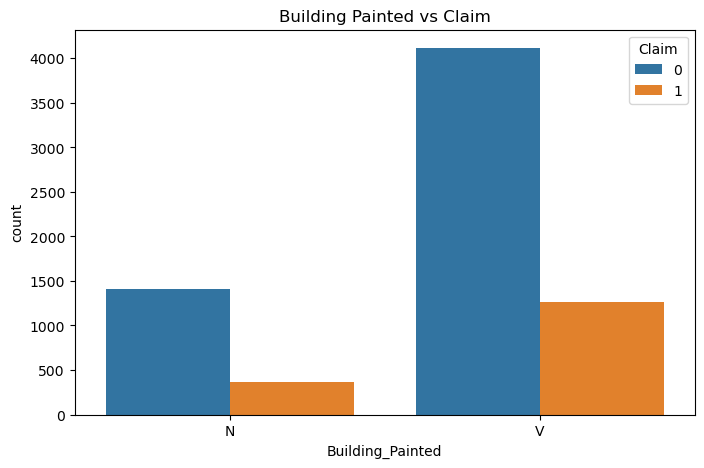

In [24]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Building_Painted',
    hue='Claim',
    data=train_df
)

plt.title('Building Painted vs Claim')
plt.show()

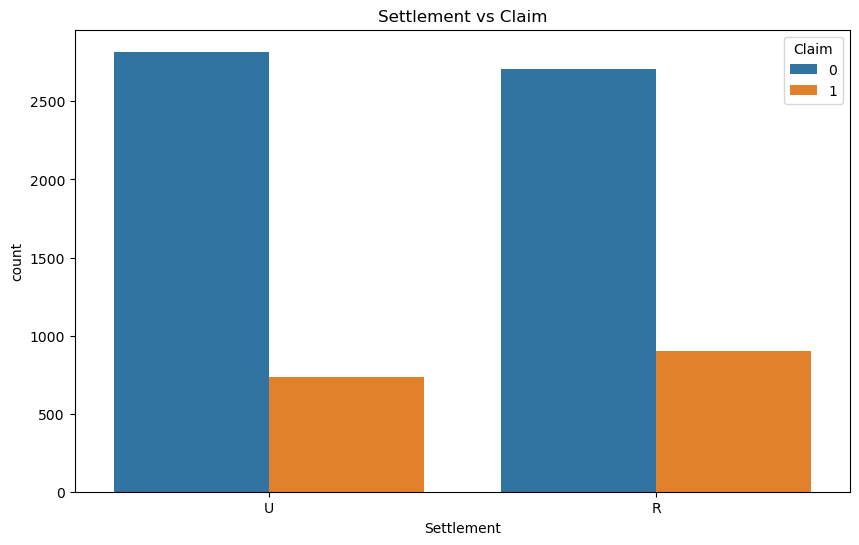

In [25]:
plt.figure(figsize=(10,6))

sns.countplot(
    x='Settlement',
    hue='Claim',
    data=train_df
)

plt.title('Settlement vs Claim')
plt.show()

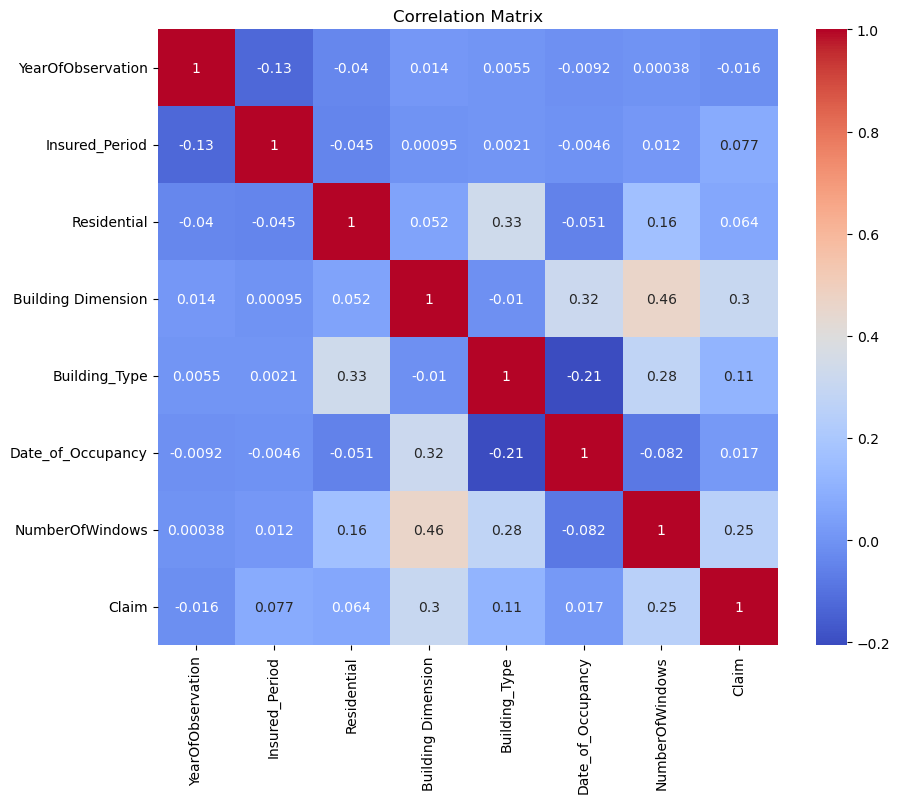

In [26]:
plt.figure(figsize=(10,8))

corr = train_df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

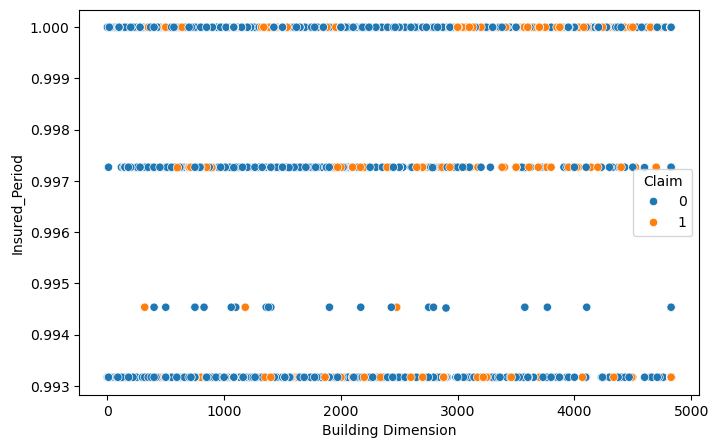

In [27]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='Building Dimension',
    y='Insured_Period',
    hue='Claim',
    data=train_df
)

plt.show()

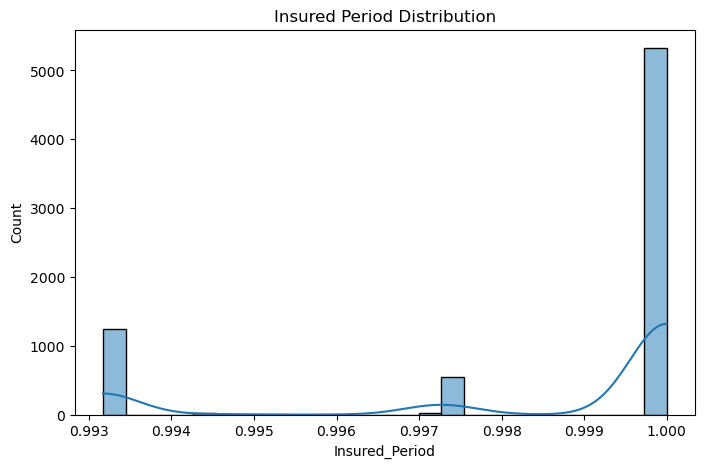

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(
    train_df['Insured_Period'],
    kde=True
)

plt.title('Insured Period Distribution')
plt.show()

Feature Transformation and Engineering

In [29]:
train_copy = train_df.copy()
test_copy = test_df.copy()

Label Encoding

In [30]:
le = LabelEncoder()

for col in train_copy.select_dtypes(include='object').columns:

    if col != 'Customer Id':

        train_copy[col] = le.fit_transform(
            train_copy[col].astype(str)
        )

        if col in test_copy.columns:
            test_copy[col] = le.fit_transform(
                test_copy[col].astype(str)
            )

Min-Max Scaling

In [31]:
scaler = MinMaxScaler()

num_cols = train_copy.select_dtypes(
    include=['int64','float64']
).columns

In [32]:
scale_cols = [c for c in num_cols if c != 'Claim']

train_copy[scale_cols] = scaler.fit_transform(
    train_copy[scale_cols]
)

test_copy[scale_cols] = scaler.transform(
    test_copy[scale_cols]
)

MERGE TRAIN & TEST....Dataset Integration

In [33]:
final_dataset = pd.concat(
    [train_copy, test_copy],
    axis=0,
    ignore_index=True
)

print(final_dataset.shape)

(10229, 14)


Export Final Dataset

In [34]:
final_dataset.to_csv(
    "Machine_Learning_Ready_Dataset.csv",
    index=False
)

print("Dataset Exported Successfully")

Dataset Exported Successfully
